In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import seaborn as sns
from ydata_profiling import ProfileReport
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

C:\Users\original store\AppData\Local\Temp\ipykernel_19388\136154303.py:7: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [2]:
df=pd.read_csv(r"D:\Level_3\Cloud\Task_DR\cloudProj\HousingData.csv")

# EDA

In [3]:
dfcopy=df.copy()

In [4]:
df.shape

(506, 14)

In [5]:
df.columns

Index(['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX',
       'PTRATIO', 'B', 'LSTAT', 'MEDV'],
      dtype='object')

In [6]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [7]:
df.tail()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,NaN,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0
505,0.04741,0.0,11.93,0.0,0.573,6.030,NaN,2.5050,1,273,21.0,396.90,7.88,11.9


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CRIM,486.0,3.611874,8.720192,0.00632,0.081900,0.253715,3.560263,88.9762
ZN,486.0,11.211934,23.388876,0.00000,0.000000,0.000000,12.500000,100.0000
INDUS,486.0,11.083992,6.835896,0.46000,5.190000,9.690000,18.100000,27.7400
CHAS,486.0,0.069959,0.255340,0.00000,0.000000,0.000000,0.000000,1.0000
NOX,506.0,0.554695,0.115878,0.38500,0.449000,0.538000,0.624000,0.8710
RM,506.0,6.284634,0.702617,3.56100,5.885500,6.208500,6.623500,8.7800
AGE,486.0,68.518519,27.999513,2.90000,45.175000,76.800000,93.975000,100.0000
DIS,506.0,3.795043,2.105710,1.12960,2.100175,3.207450,5.188425,12.1265
RAD,506.0,9.549407,8.707259,1.00000,4.000000,5.000000,24.000000,24.0000
TAX,506.0,408.237154,168.537116,187.00000,279.000000,330.000000,666.000000,711.0000


In [10]:
df.isnull().sum()/len(df) * 100

CRIM       3.952569
ZN         3.952569
INDUS      3.952569
CHAS       3.952569
NOX        0.000000
RM         0.000000
AGE        3.952569
DIS        0.000000
RAD        0.000000
TAX        0.000000
PTRATIO    0.000000
B          0.000000
LSTAT      3.952569
MEDV       0.000000
dtype: float64

In [11]:
df.duplicated().sum()

np.int64(0)

- DATA CLEANING

In [12]:
# Keep all rows and handle missing values inside the model pipeline
df = df.copy()

In [13]:
df

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,NaN,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


- univariate analysis

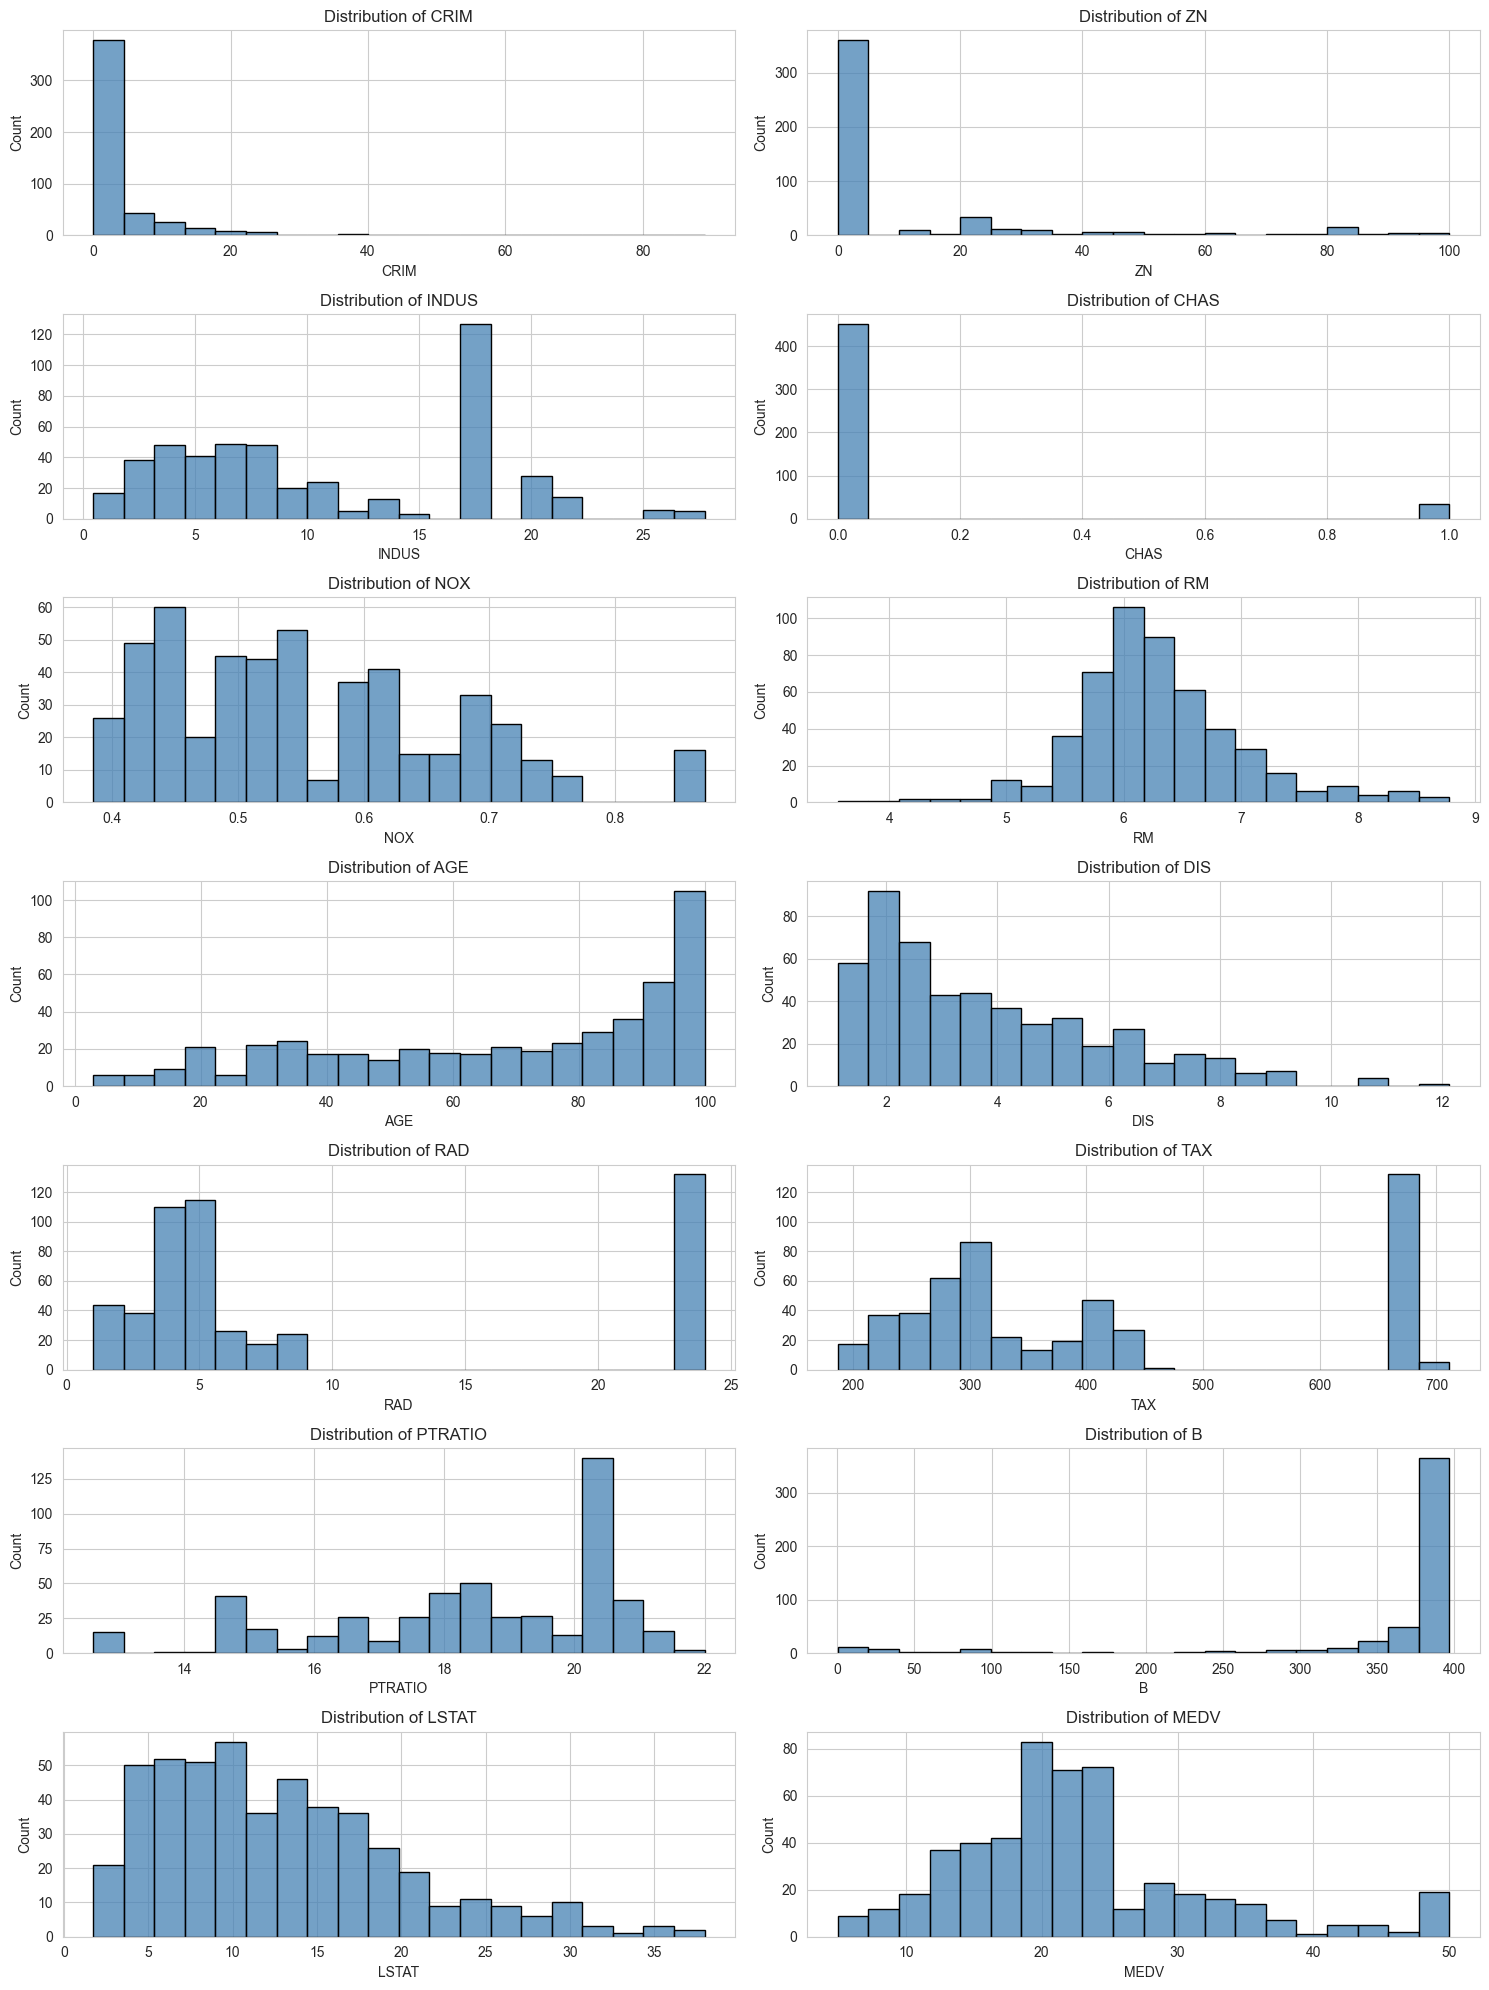

In [14]:
fig, axes = plt.subplots(7, 2, figsize=(15, 20))
axes = axes.ravel()

columns = df.columns.tolist()

for idx, col in enumerate(columns):
    sns.histplot(df[col], bins=20, kde=False, ax=axes[idx], color='steelblue', edgecolor='black')
    axes[idx].set_title(f'Distribution of {col}')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Count')

plt.tight_layout()
plt.show()

- outlayers detect with boxplot

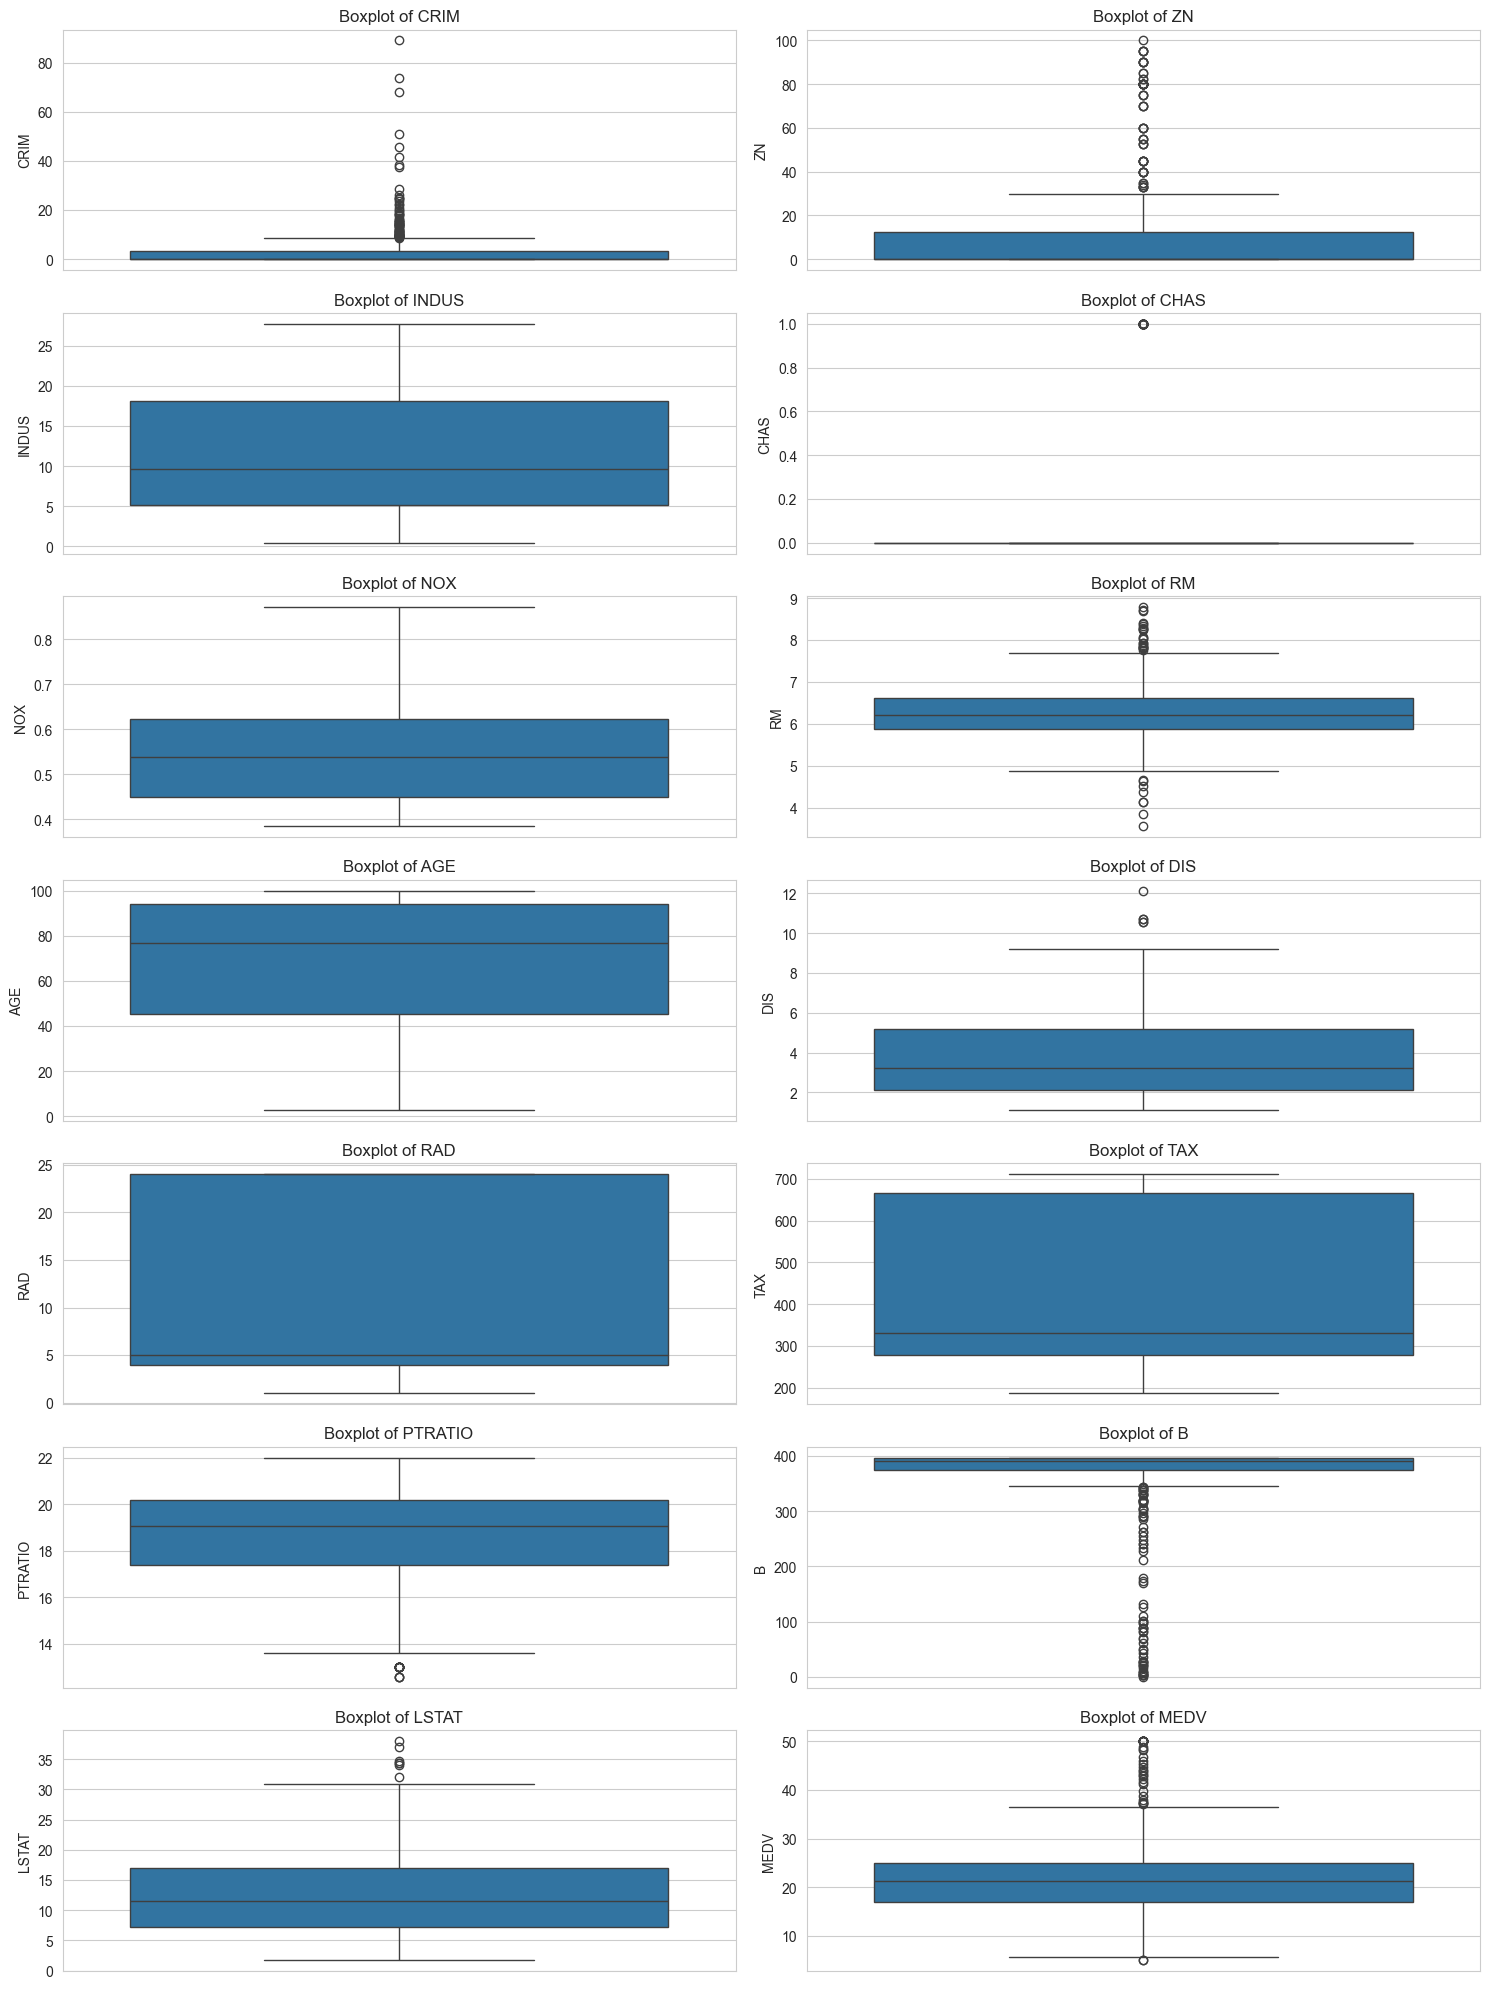

In [15]:
fig, axes = plt.subplots(7, 2, figsize=(15, 20))
axes = axes.ravel()

columns = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

for idx, col in enumerate(columns):
    sns.boxplot(y=df[col], ax=axes[idx])
    axes[idx].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

- handling outlayers with box and histograms

In [16]:
df['CRIM'] = np.log1p(df['CRIM'])

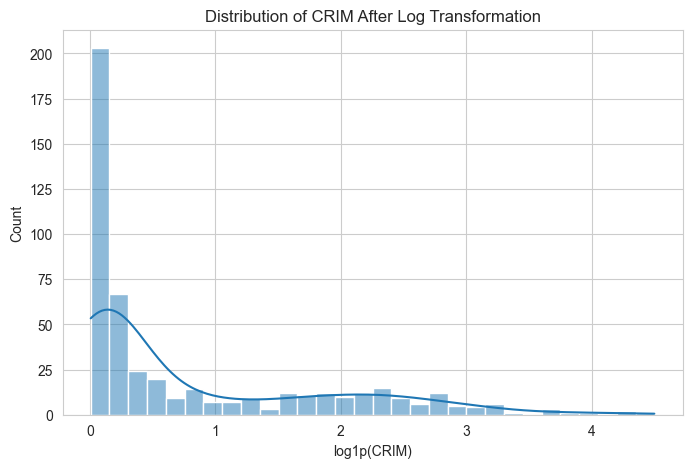

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(df['CRIM'], bins=30, kde=True)

plt.title('Distribution of CRIM After Log Transformation')
plt.xlabel('log1p(CRIM)')
plt.ylabel('Count')

plt.show()

- number of outlayers

In [18]:
outlier_columns = ['CRIM', 'RM', 'DIS', 'B', 'LSTAT']

for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {outliers}")

CRIM: 6
RM: 30
DIS: 5
B: 77
LSTAT: 7


- I tried several methods to handle the left-skewed B feature. The reflection and log transformation approach produced the best results, since log transformation is more effective for right-skewed distributions.

In [19]:
x_reflected = df['B'].max() + 1 - df['B']
df['B_log'] = np.log1p(x_reflected)

In [20]:
outlier_columns = ['CRIM', 'RM', 'DIS', 'B', 'LSTAT', 'B_log']

for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {outliers}")

CRIM: 6
RM: 30
DIS: 5
B: 77
LSTAT: 7
B_log: 0


- I realized that the problem was not the distribution, but the feature values themselves. Although I applied reflection and log transformation, the improvement was minimal, so I decided to ues B_log any way.

In [21]:
df.drop('B', axis=1, inplace=True)

In [22]:
df

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV,B_log
0,0.006300,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0,0.693147
1,0.026944,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6,0.693147
2,0.026924,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7,1.803359
3,0.031857,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4,1.451614
4,0.066770,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,NaN,36.2,0.693147
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.060747,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1,273,21.0,NaN,22.4,1.932970
502,0.044275,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6,0.693147
503,0.058986,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9,0.693147
504,0.103991,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0,1.695616


- Bivariate Analysis

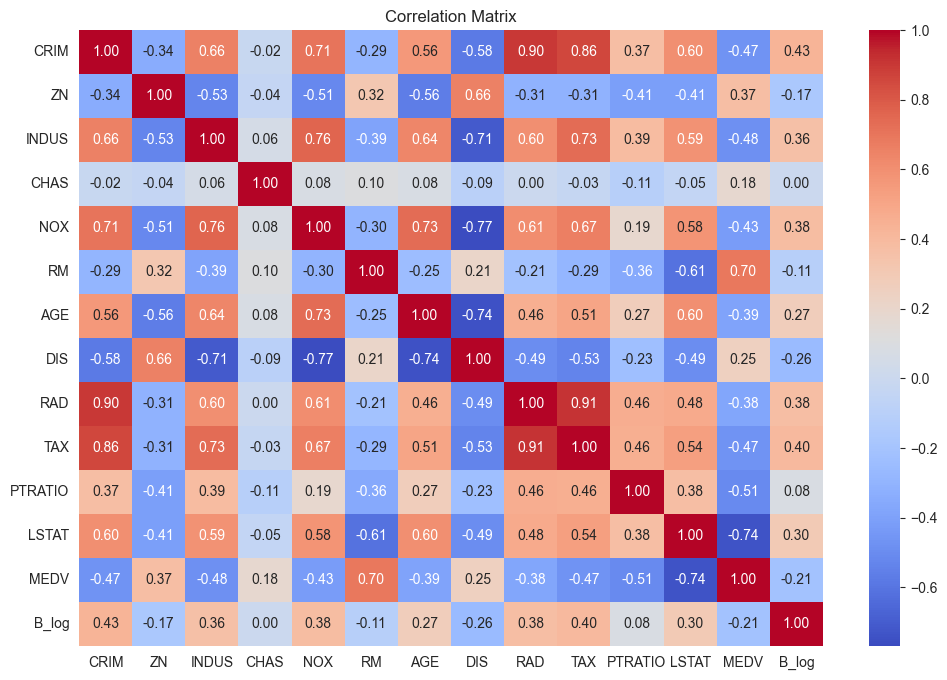

In [23]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")

plt.title("Correlation Matrix")

plt.show()

- LSTAT has the strongest negative correlation with MEDV

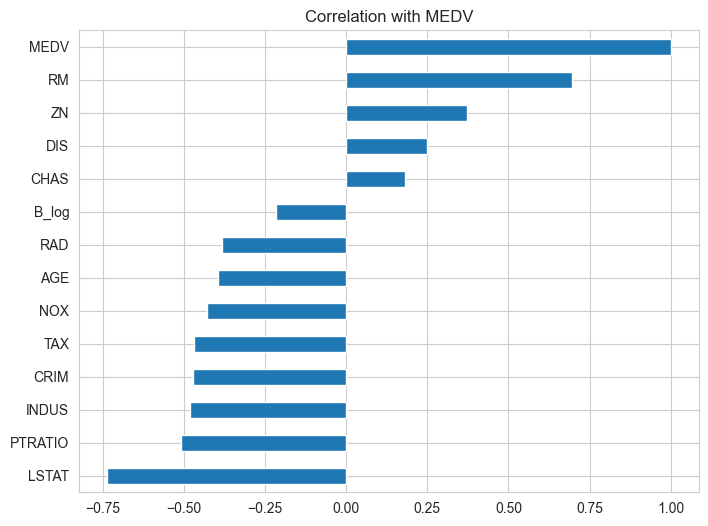

In [24]:
corr = df.corr()['MEDV'].sort_values()

plt.figure(figsize=(8,6))

corr.plot(kind='barh')

plt.title("Correlation with MEDV")

plt.show()

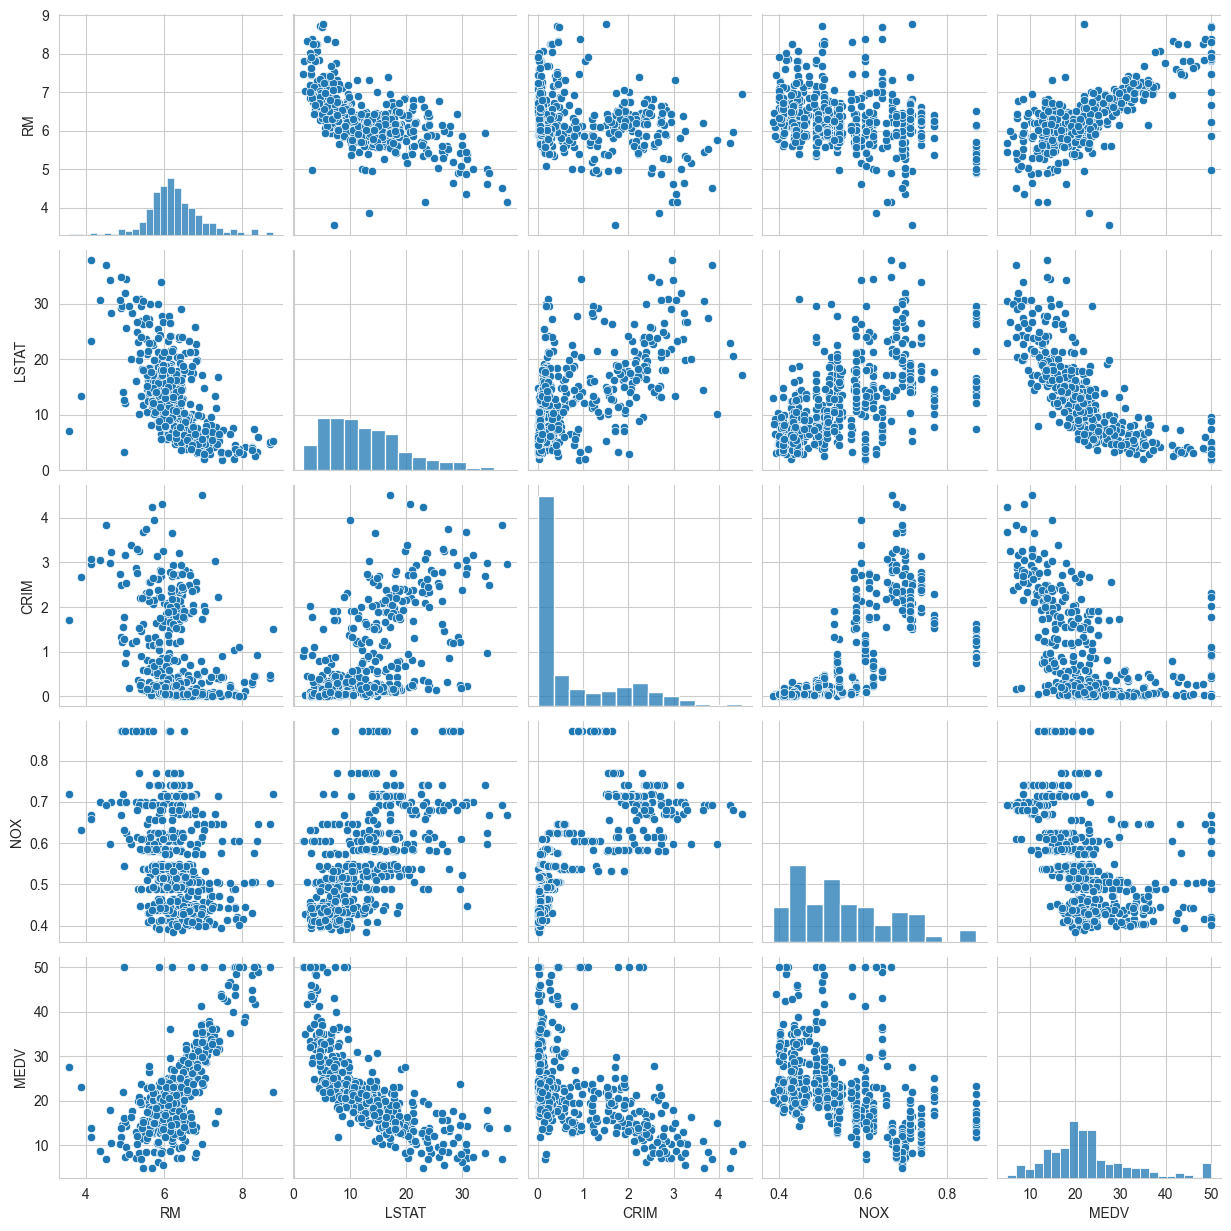

In [25]:
sns.pairplot( df[['RM','LSTAT','CRIM','NOX','MEDV']])

plt.show()

- 1: The average number of rooms (RM) has a strong positive correlation with house prices (MEDV). Houses with more rooms tend to have higher prices.

- 2: LSTAT has a strong negative correlation with MEDV. As the percentage of lower-status population increases, house prices decrease.

- 3: Higher crime rates (CRIM) are generally associated with lower house prices, indicating a negative relationship between crime and property values.

- 4: Higher nitric oxide concentration (NOX) is associated with lower house prices, suggesting that areas with higher pollution levels tend to have lower property values.

- 5: RM and LSTAT have a strong negative relationship. Areas with more rooms generally have a lower percentage of lower-status population.

# feature engineering

In [26]:
df['RM_CRIM'] = df['RM'] / (df['CRIM'] + 1)

- Houses with more rooms and lower crime rates are generally more valuable

In [27]:
df['CRIM_NOX'] = df['CRIM'] * df['NOX']

- areas with pollution may have lower property values 

In [28]:
df['AGE_DIS'] = df['AGE'] * df['DIS']

In [29]:
df

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV,B_log,RM_CRIM,CRIM_NOX,AGE_DIS
0,0.006300,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0,0.693147,6.533836,0.003389,266.66800
1,0.026944,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6,0.693147,6.252533,0.012637,391.90419
2,0.026924,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7,1.803359,6.996621,0.012627,303.48981
3,0.031857,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4,1.451614,6.781947,0.014591,277.64876
4,0.066770,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,NaN,36.2,0.693147,6.699661,0.030581,328.57124
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.060747,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1,273,21.0,NaN,22.4,1.932970,6.215431,0.034808,171.27126
502,0.044275,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6,0.693147,5.860524,0.025370,175.45125
503,0.058986,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9,0.693147,6.587436,0.033799,197.24250
504,0.103991,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0,1.695616,6.154038,0.059587,213.32877


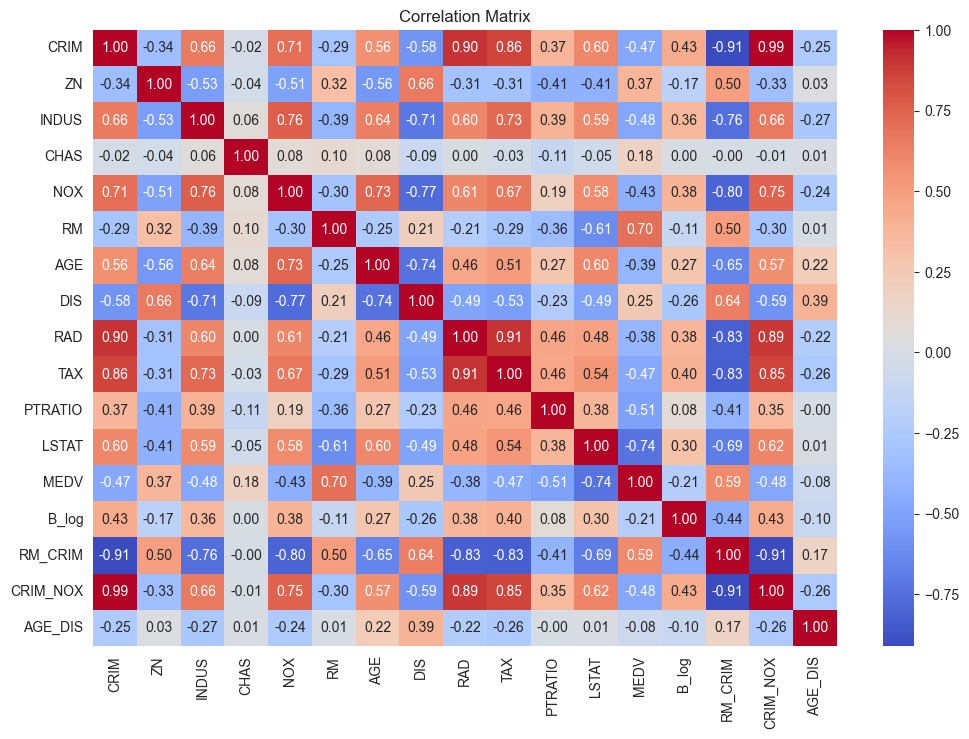

In [30]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")

plt.title("Correlation Matrix")

plt.show()

In [31]:
corr = df.corr()['MEDV'].sort_values(ascending=False)
corr

MEDV        1.000000
RM          0.695360
RM_CRIM     0.590863
ZN          0.373136
DIS         0.249929
CHAS        0.181391
AGE_DIS    -0.078314
B_log      -0.214994
RAD        -0.381626
AGE        -0.394656
NOX        -0.427321
TAX        -0.468536
CRIM       -0.471534
INDUS      -0.481772
CRIM_NOX   -0.484974
PTRATIO    -0.507787
LSTAT      -0.735822
Name: MEDV, dtype: float64

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df.drop('MEDV', axis=1)
y = df['MEDV']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

linear_model = make_pipeline(
    SimpleImputer(strategy='median'),
    LinearRegression()
)
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

print('Linear Regression')
print('R2:', r2_score(y_test, linear_pred))
print('MAE:', mean_absolute_error(y_test, linear_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, linear_pred)))

Linear Regression
R2: 0.6825383144494086
MAE: 3.014262946375694
RMSE: 4.8250042911771285


In [33]:
rf_model = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    )
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print('Random Forest')
print('R2:', r2_score(y_test, rf_pred))
print('MAE:', mean_absolute_error(y_test, rf_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, rf_pred)))

Random Forest
R2: 0.8694156062665346
MAE: 2.03402188829176
RMSE: 3.0945512783232703


In [34]:
importances = pd.Series(
    rf_model.named_steps['randomforestregressor'].feature_importances_,
    index=X.columns
).sort_values(ascending=False)

selected_features = importances.head(10).index

X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

rf_selected_model = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    )
)

rf_selected_model.fit(X_train_sel, y_train)
rf_selected_pred = rf_selected_model.predict(X_test_sel)

print('Random Forest with selected features')
print('R2:', r2_score(y_test, rf_selected_pred))
print('MAE:', mean_absolute_error(y_test, rf_selected_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, rf_selected_pred)))

Random Forest with selected features
R2: 0.8760902793568732
MAE: 1.9809974112318027
RMSE: 3.014426742367319


In [35]:
rf2 = RandomForestRegressor(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)

rf2.fit(X_train_sel, y_train)
pred = rf2.predict(X_test_sel)

print('Random Forest (selected features only)')
print('R2:', r2_score(y_test, pred))
print('MAE:', mean_absolute_error(y_test, pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, pred)))

Random Forest (selected features only)
R2: 0.8793352493033646
MAE: 1.9335631383083884
RMSE: 2.974693709053336


In [36]:
results = {
    'Linear Regression': {
        'R2': r2_score(y_test, linear_pred),
        'MAE': mean_absolute_error(y_test, linear_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, linear_pred)),
    },
    'Random Forest': {
        'R2': r2_score(y_test, rf_pred),
        'MAE': mean_absolute_error(y_test, rf_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, rf_pred)),
    },
    'Random Forest with selected features': {
        'R2': r2_score(y_test, rf_selected_pred),
        'MAE': mean_absolute_error(y_test, rf_selected_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, rf_selected_pred)),
    },
}

for name, metrics in results.items():
    print(name)
    for metric, value in metrics.items():
        print(f'{metric}: {value:.4f}')
    print()

Linear Regression
R2: 0.6825
MAE: 3.0143
RMSE: 4.8250

Random Forest
R2: 0.8694
MAE: 2.0340
RMSE: 3.0946

Random Forest with selected features
R2: 0.8761
MAE: 1.9810
RMSE: 3.0144



In [37]:

import joblib
from pathlib import Path

# اسم الموديل الأفضل عندك
best_model = rf_selected_model  # غيّر الاسم حسب كودك

# قائمة الـ Features المستخدمة في تدريب الموديل
# غيّر selected_features لاسم القائمة الموجودة عندك
feature_names = list(selected_features)

# مكان حفظ الملف
save_path = Path.home() / "Downloads" / "best_random_forest.joblib"
save_path.parent.mkdir(parents=True, exist_ok=True)

# حفظ الموديل والـ Features معًا
joblib.dump({
    "model": best_model,
    "features": feature_names
}, save_path)

print("Model saved successfully!")
print("Location:", save_path)


Model saved successfully!
Location: C:\Users\original store\Downloads\best_random_forest.joblib


In [38]:
import joblib
from pathlib import Path

model_path = (
    Path.home()
    / "Downloads"
    / "best_random_forest.joblib"
)

saved_data = joblib.load(model_path)

model = saved_data["model"]
features = saved_data["features"]

print("Model loaded successfully!")
print("Number of features:", len(features))
print("Features:", features)

Model loaded successfully!
Number of features: 10
Features: ['RM', 'LSTAT', 'DIS', 'PTRATIO', 'CRIM_NOX', 'RM_CRIM', 'CRIM', 'TAX', 'AGE_DIS', 'NOX']
